# Capstone, Notebook 1: Problem Definition, Data Preparation and EDA
**Task 6: Final Data Science Capstone** - AI ML Research Specialist Internship

# Day-Ahead Hourly Demand Forecasting for a City Bike-Share System

| Notebook 1 (this one) | Notebook 2 |
|---|---|
| 1 Problem definition | 6 Modelling and validation design |
| 2 Data collection and provenance | 7 Evaluation and statistical comparison |
| 3 Data audit | 8 Interpretation and error analysis |
| 4 Cleaning and preprocessing | 9 Uncertainty and operational planning |
| 5 Exploratory data analysis | 10 Recommendations, limitations, future scope |

## 1. Problem definition

**Business context.** A bike-share operator must decide, a day ahead, how many bikes to position where, and when to schedule rebalancing crews and maintenance. Demand swings by a factor of 50 between a 4 a.m. and a 5 p.m. commuter hour, depends strongly on weather, and the system grew about 64% in one year. Poor forecasts mean empty docks at rush hour (lost trips) or idle bikes and wasted crew time.

**Problem statement.** Forecast the **total number of bike rentals in each hour** of the next day, using information available the day before, and quantify the uncertainty so the operator can choose a planning level.

**Objectives**
1. Build a documented, reproducible pipeline from raw data to forecasts.
2. Identify what drives demand (time of day, working day, weather, growth) with statistical evidence.
3. Compare baselines, a statistical model and machine-learning models under a **time-respecting** validation design.
4. Provide prediction intervals and a planning trade-off between shortages and surplus.
5. Convert findings into operational recommendations, with limitations stated honestly.

**Scope.** System-wide hourly totals (not stations); Washington DC Capital Bikeshare 2011-2012. *In scope:* day-ahead forecasting (history available up to 24 hours before the target hour), plus an hour-ahead comparison to measure the value of real-time data. *Out of scope:* station-level flows, rebalancing route optimisation, pricing.

**Requirements.** No leakage (a forecast for hour t may use demand only up to t-24 h); chronological train/validation/test split; test set used once; every cleaning decision logged and tested; random seeds fixed.

**Success criteria (declared before any modelling)**
| # | Criterion |
|---|---|
| S1 | On the held-out test quarter, the day-ahead model's WAPE is at least **25% lower** (relative) than the best naive baseline |
| S2 | Test WAPE is at most **25%** |
| S3 | The nominal 80% prediction interval has empirical test coverage between **70% and 90%** |
| S4 | All leakage and data-cleaning unit tests pass |

WAPE = sum of absolute errors / sum of actual demand (well defined even when some hours have zero demand).

**Expected outcomes.** Cleaned dataset, validated forecasting models, interpretable drivers, interval forecasts, operational recommendations, report and presentation.

In [1]:
import sys, json, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.tsa.stattools import acf

sys.path.insert(0, str(Path.cwd().parent / "src")) if Path.cwd().name == "notebooks" else sys.path.insert(0, str(Path.cwd() / "src"))
from bikeshare import clean_hourly, load_raw

warnings.filterwarnings("ignore", category=FutureWarning)
SEED = 42; rng = np.random.default_rng(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG, TAB, PROC = ROOT / "outputs" / "figures", ROOT / "outputs" / "tables", ROOT / "data" / "processed"
for p in (FIG, TAB, PROC): p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook"); ORANGE, BLUE, GREY, GREEN = "#E8590C", "#1971C2", "#868e96", "#2F9E44"
M = {}
def save_fig(fig, name):
    fig.tight_layout(); fig.savefig(FIG / name, dpi=140, bbox_inches="tight"); plt.show()
def must(cond, msg):
    assert cond, "INTEGRITY CHECK FAILED: " + msg; print("[OK]", msg)

## 2. Data collection and provenance
**Source:** UCI Machine Learning Repository, *Bike Sharing Dataset* (Fanaee-T and Gama, 2013; DOI 10.24432/C5W894; CC BY 4.0). Rentals come from the public Capital Bikeshare system logs (Washington DC), weather from freemeteo.com, holidays from the DC government schedule. `src/download_data.py` downloads two independent public GitHub copies of the UCI file and refuses to continue unless they are byte-identical (checksum recorded in `data/SOURCE.md`).

In [2]:
raw = load_raw()
print("raw shape:", raw.shape, "| period:", raw["ts"].min(), "->", raw["ts"].max())
raw.drop(columns=["ts"]).head()

raw shape: (17379, 18) | period: 2011-01-01 00:00:00 -> 2012-12-31 23:00:00


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


## 3. Data audit
Before cleaning, check structure, completeness, internal consistency and sensor quality. Each finding drives a documented decision in Section 4.

In [3]:
A = {}                                                     # audit findings
A["rows"], A["cols"] = raw.shape; A["nulls"] = int(raw.isna().sum().sum()); A["dup_rows"] = int(raw.duplicated().sum()); A["dup_ts"] = int(raw["ts"].duplicated().sum())
print(f"nulls: {A['nulls']} | duplicate rows: {A['dup_rows']} | duplicate timestamps: {A['dup_ts']}")

full = pd.date_range(raw["ts"].min(), raw["ts"].max(), freq="h"); absent = full.difference(raw["ts"])
A["expected_hours"], A["absent_hours"] = len(full), len(absent); A["absent_overnight_share"] = float((absent.hour <= 5).mean())
per_day = pd.Series(1, index=absent).resample("D").sum(); per_day = per_day[per_day > 0]
big = per_day[per_day >= 6]
print(f"{len(full):,} hours expected, {len(absent)} absent ({len(absent) / len(full):.1%}); {A['absent_overnight_share']:.0%} of absent hours are between 00:00 and 05:59")
print("Days with 6+ absent hours:", {str(k.date()): int(v) for k, v in big.items()})
A["min_cnt"] = int(raw["cnt"].min()); print("minimum hourly count in the file:", A["min_cnt"], "-> the file never records an hour with zero rentals")
adj_prev = raw.set_index("ts")["cnt"].reindex(absent - pd.Timedelta(hours=1)).dropna(); adj_next = raw.set_index("ts")["cnt"].reindex(absent + pd.Timedelta(hours=1)).dropna()
A["adjacent_median"], A["overall_median"] = float(pd.concat([adj_prev, adj_next]).median()), float(raw["cnt"].median())
print(f"median demand of the existing hours next to an absent hour: {A['adjacent_median']:.0f} vs {A['overall_median']:.0f} overall: absent hours sit in low-demand periods")

# internal consistency
A["workingday_mismatch"] = int(((raw["workingday"] == 1) != (raw["weekday"].between(1, 5) & (raw["holiday"] == 0))).sum())
A["cnt_sum_mismatch"] = int((raw["cnt"] != raw["casual"] + raw["registered"]).sum())
wk_map = pd.crosstab(raw["weekday"], raw["dteday"].dt.dayofweek).idxmax(axis=1).to_dict()
print("workingday inconsistencies:", A["workingday_mismatch"], "| cnt != casual+registered:", A["cnt_sum_mismatch"], "| UCI weekday -> pandas weekday:", wk_map, "(0 = Sunday confirmed)")

# sensor quirks
A["hum_zero_rows"] = int((raw["hum"] == 0).sum()); A["hum_zero_days"] = [str(x.date()) for x in raw.loc[raw["hum"] == 0, "dteday"].unique()]
A["wind_zero_share"] = float((raw["windspeed"] == 0).mean()); A["wind_floor_kmh"] = float(raw.loc[raw["windspeed"] > 0, "windspeed"].min() * 67)
A["weathersit4_rows"] = int((raw["weathersit"] == 4).sum()); A["weathersit_counts"] = raw["weathersit"].value_counts().sort_index().to_dict()
tc, ac = raw["temp"] * 47 - 8, raw["atemp"] * 66 - 16; coef = np.polyfit(tc, ac, 1); res = ac - np.polyval(coef, tc); z = (res - res.mean()) / res.std()
A["atemp_outlier_rows"] = int((z.abs() > 4).sum()); A["atemp_outlier_days"] = [str(x.date()) for x in raw.loc[z.abs() > 4, "dteday"].unique()]; A["temp_atemp_r"] = float(np.corrcoef(tc, ac)[0, 1])
print(f"humidity == 0: {A['hum_zero_rows']} rows on {A['hum_zero_days']} | wind speed == 0: {A['wind_zero_share']:.1%} of rows (smallest positive reading {A['wind_floor_kmh']:.1f} km/h: a measurement floor)")
print(f"weathersit 4 (heavy rain/snow): {A['weathersit4_rows']} rows | feels-like temperature glitches on {A['atemp_outlier_days']} (temp vs atemp r = {A['temp_atemp_r']:.3f})")
M["audit"] = A

nulls: 0 | duplicate rows: 0 | duplicate timestamps: 0
17,544 hours expected, 165 absent (0.9%); 67% of absent hours are between 00:00 and 05:59
Days with 6+ absent hours: {'2011-01-18': 12, '2011-01-26': 8, '2011-01-27': 16, '2011-02-22': 6, '2011-08-27': 6, '2011-08-28': 7, '2012-10-29': 23, '2012-10-30': 13}
minimum hourly count in the file: 1 -> the file never records an hour with zero rentals
median demand of the existing hours next to an absent hour: 3 vs 142 overall: absent hours sit in low-demand periods
workingday inconsistencies: 0 | cnt != casual+registered: 0 | UCI weekday -> pandas weekday: {0: 6, 1: 0, 2: 1, 3: 2, 4: 3, 5: 4, 6: 5} (0 = Sunday confirmed)
humidity == 0: 22 rows on ['2011-03-10'] | wind speed == 0: 12.5% of rows (smallest positive reading 6.0 km/h: a measurement floor)
weathersit 4 (heavy rain/snow): 3 rows | feels-like temperature glitches on ['2011-07-21', '2011-07-22', '2012-08-17'] (temp vs atemp r = 0.988)


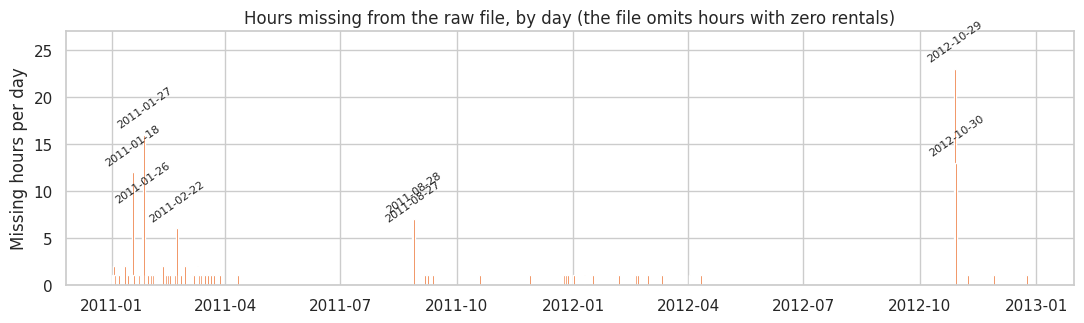

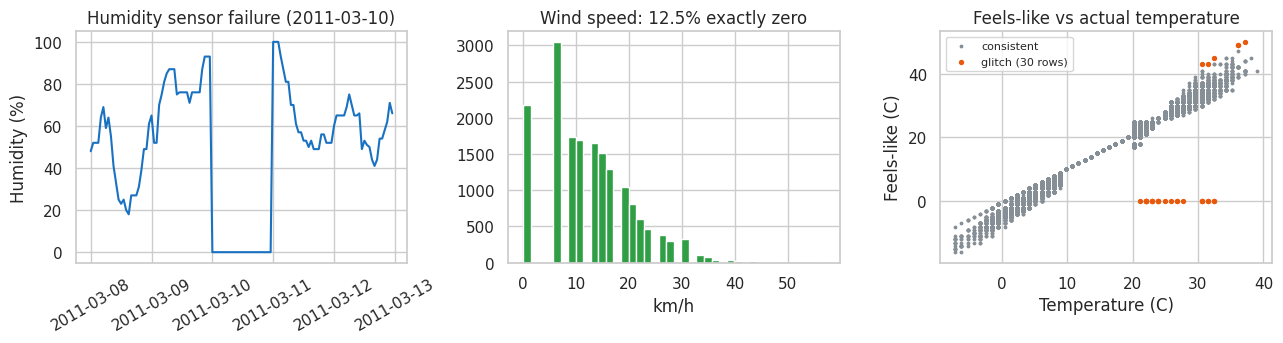

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.4))
ax.bar(per_day.index, per_day.values, width=1.5, color=ORANGE)
for d, v in big.items(): ax.annotate(str(d.date()), (d, v), textcoords="offset points", xytext=(0, 5), ha="center", fontsize=8, rotation=35)
ax.set(title="Hours missing from the raw file, by day (the file omits hours with zero rentals)", ylabel="Missing hours per day"); ax.set_ylim(0, 27)
save_fig(fig, "t6_01_missing_hours.png")
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
h = raw[(raw["ts"] >= "2011-03-08") & (raw["ts"] < "2011-03-13")]; axes[0].plot(h["ts"], h["hum"] * 100, color=BLUE); axes[0].set(title="Humidity sensor failure (2011-03-10)", ylabel="Humidity (%)"); axes[0].tick_params(axis="x", rotation=30)
axes[1].hist(raw["windspeed"] * 67, bins=40, color=GREEN); axes[1].set(title=f"Wind speed: {A['wind_zero_share']:.1%} exactly zero", xlabel="km/h")
ok = z.abs() <= 4; axes[2].scatter(tc[ok], ac[ok], s=3, color=GREY, label="consistent"); axes[2].scatter(tc[~ok], ac[~ok], s=8, color=ORANGE, label=f"glitch ({int((~ok).sum())} rows)")
axes[2].set(title="Feels-like vs actual temperature", xlabel="Temperature (C)", ylabel="Feels-like (C)"); axes[2].legend(fontsize=8)
save_fig(fig, "t6_02_sensor_quirks.png")

### Audit findings and decisions
| Finding | Evidence | Decision |
|---|---|---|
| No hour has zero rentals; 165 hours are absent | minimum count is 1; 67% of absent hours are overnight and the rest cluster on storm days; neighbouring hours have very low demand | Treat absent hours as **zero demand** (documented assumption; tested in notebook 2) |
| Humidity = 0 on 2011-03-10 | 22 rows, one day | Mark as missing and interpolate in time |
| Wind speed = 0 for 12.5% of rows | smallest positive reading is 6 km/h: a measurement floor | Keep, add a `wind_calm` flag |
| Feels-like temperature glitches | rows far off the temp/atemp line, r = 0.99 otherwise | **Drop** `atemp` from models (redundant with `temp`) |
| weathersit 4 occurs 3 times | too rare to estimate | Merge into category 3 (rain/snow) |
| UCI weekday coding | 0 = Sunday verified | Keep, recompute for absent hours |

## 4. Cleaning and preprocessing

In [5]:
df, audit = clean_hourly(raw)
print(audit)
must(len(df) == audit["expected_hours"] == 17544 and df.index.is_unique, "complete regular hourly index: 17,544 hours")
must(df["cnt"].sum() == raw["cnt"].sum(), "total demand unchanged by cleaning (no demand created or lost)")
must(not df.isna().any().any(), "no missing values remain")
must((df["casual"] + df["registered"] == df["cnt"]).all(), "casual + registered = total in every hour")
must(df["hum_pct"].min() > 0 and df["weathersit"].max() == 3, "humidity glitch repaired; weather categories merged")
clean_log = pd.DataFrame([
    ("Reindex to a complete hourly series", f"{audit['missing_hours']} absent hours added", "treated as zero rentals"),
    ("Calendar fields recomputed for added hours", "weekday (0 = Sunday), season, holiday, working day", "taken from the same day / timestamp"),
    ("Humidity sensor failure", f"{audit['humidity_zero_rows']} rows", "set missing, interpolated in time"),
    ("Weather for added hours", f"{audit['missing_hours']} rows", "interpolated in time; weathersit carried from neighbours"),
    ("Rare weather category 4", f"{audit['weathersit4_rows']} rows", "merged into category 3"),
    ("Wind speed zeros", f"{audit['wind_zero_share']:.1%} of rows", "kept; wind_calm flag added"),
    ("Units", "temp, humidity, wind", "converted to degrees C, percent, km/h"),
    ("atemp", f"{A['atemp_outlier_rows']} glitch rows", "excluded from modelling"),
], columns=["Step", "Scope", "Treatment"]); M["clean_log"] = clean_log.values.tolist()
df.to_csv(PROC / "hourly_clean.csv"); display(clean_log)
M["clean"] = {k: (float(v) if isinstance(v, (np.floating,)) else v) for k, v in audit.items()}

{'raw_rows': 17379, 'expected_hours': 17544, 'missing_hours': 165, 'missing_overnight_share': 0.6666666666666666, 'humidity_zero_rows': 22, 'weathersit4_rows': 3, 'wind_zero_share': 0.12443000455996352, 'clean_rows': 17544}
[OK] complete regular hourly index: 17,544 hours
[OK] total demand unchanged by cleaning (no demand created or lost)
[OK] no missing values remain
[OK] casual + registered = total in every hour
[OK] humidity glitch repaired; weather categories merged


,Step,Scope,Treatment
0,Reindex to a complete hourly series,165 absent hours added,treated as zero rentals
1,Calendar fields recomputed for added hours,"weekday (0 = Sunday), season, holiday, working...",taken from the same day / timestamp
2,Humidity sensor failure,22 rows,"set missing, interpolated in time"
3,Weather for added hours,165 rows,interpolated in time; weathersit carried from ...
4,Rare weather category 4,3 rows,merged into category 3
5,Wind speed zeros,12.4% of rows,kept; wind_calm flag added
6,Units,"temp, humidity, wind","converted to degrees C, percent, km/h"
7,atemp,30 glitch rows,excluded from modelling


## 5. Exploratory data analysis

### 5.1 The target: heavy-tailed, strongly overdispersed counts

mean 187.7, variance 32926, variance/mean = 175 (Poisson would be 1). Even within year-hour-daytype cells the median variance/mean is 33.
-> Poisson regression would understate uncertainty; use negative-binomial/Poisson-type models with overdispersion in mind and judge by hold-out error.


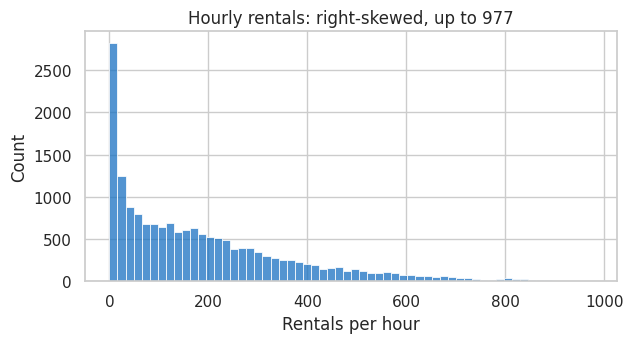

In [6]:
y = df["cnt"]; M["cnt_mean"], M["cnt_var"], M["cnt_max"] = float(y.mean()), float(y.var()), int(y.max()); M["vmr"] = float(y.var() / y.mean())
cell = df.groupby(["yr", "hr", "workingday"])["cnt"].agg(["mean", "var"]); M["vmr_cell_median"] = float((cell["var"] / cell["mean"]).median())
print(f"mean {y.mean():.1f}, variance {y.var():.0f}, variance/mean = {M['vmr']:.0f} (Poisson would be 1). Even within year-hour-daytype cells the median variance/mean is {M['vmr_cell_median']:.0f}.")
print("-> Poisson regression would understate uncertainty; use negative-binomial/Poisson-type models with overdispersion in mind and judge by hold-out error.")
fig, ax = plt.subplots(figsize=(6.5, 3.6)); sns.histplot(y, bins=60, color=BLUE, ax=ax); ax.set(title="Hourly rentals: right-skewed, up to 977", xlabel="Rentals per hour")
save_fig(fig, "t6_03_target_distribution.png")

### 5.2 Growth: demand rose sharply from 2011 to 2012

mean hourly demand 2011 = 141.9, 2012 = 233.3: growth +64.4% (bootstrap 95% CI +55.8% to +73.5%)


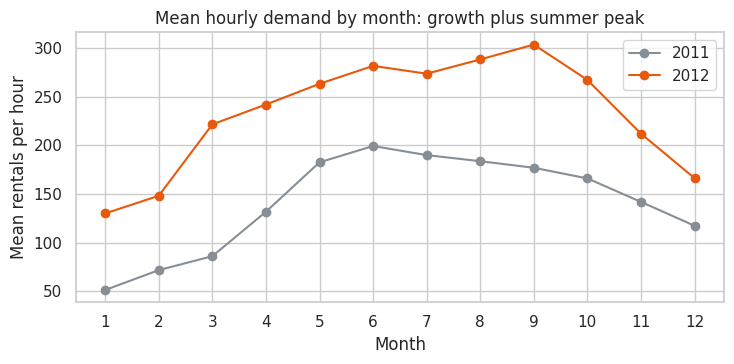

In [7]:
daily = df["cnt"].groupby(df.index.normalize()).mean(); d11, d12 = daily[daily.index.year == 2011].to_numpy(), daily[daily.index.year == 2012].to_numpy()
growth = d12.mean() / d11.mean() - 1
boot = [rng.choice(d12, len(d12)).mean() / rng.choice(d11, len(d11)).mean() - 1 for _ in range(4000)]; glo, ghi = np.percentile(boot, [2.5, 97.5])
M["growth"], M["growth_ci"] = float(growth), [float(glo), float(ghi)]
print(f"mean hourly demand 2011 = {d11.mean():.1f}, 2012 = {d12.mean():.1f}: growth {growth:+.1%} (bootstrap 95% CI {glo:+.1%} to {ghi:+.1%})")
monthly = df["cnt"].groupby([df.index.year, df.index.month]).mean().unstack(0)
fig, ax = plt.subplots(figsize=(7.5, 3.8)); ax.plot(monthly.index, monthly[2011], "o-", color=GREY, label="2011"); ax.plot(monthly.index, monthly[2012], "o-", color=ORANGE, label="2012")
ax.set(title="Mean hourly demand by month: growth plus summer peak", xlabel="Month", ylabel="Mean rentals per hour", xticks=range(1, 13)); ax.legend()
save_fig(fig, "t6_04_growth.png"); M["monthly"] = {int(k): {"2011": float(v[2011]), "2012": float(v[2012])} for k, v in monthly.iterrows()}

### 5.3 Daily rhythm: commuters versus leisure riders

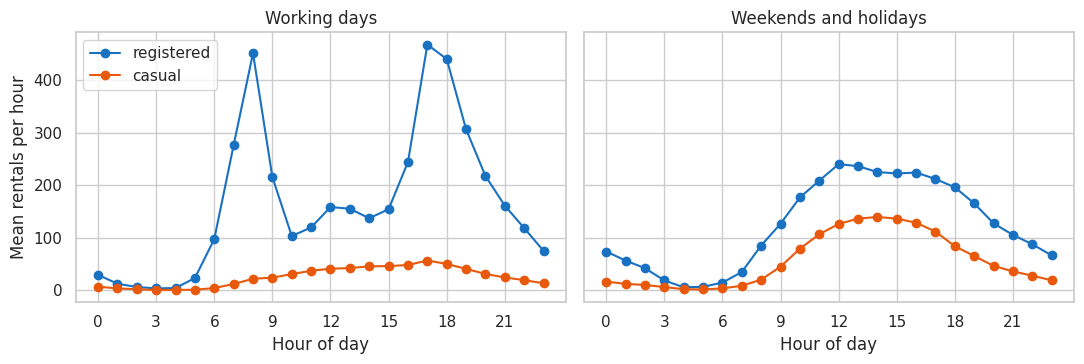

Working days: peaks at 8:00 (473) and 17:00 (524); midday trough ~188. Weekends: single midday/afternoon plateau peaking at 13:00 (373).
Casual riders are 31.7% of weekend/holiday demand vs 13.2% on working days (daily-share Mann-Whitney p = 1.9e-68).


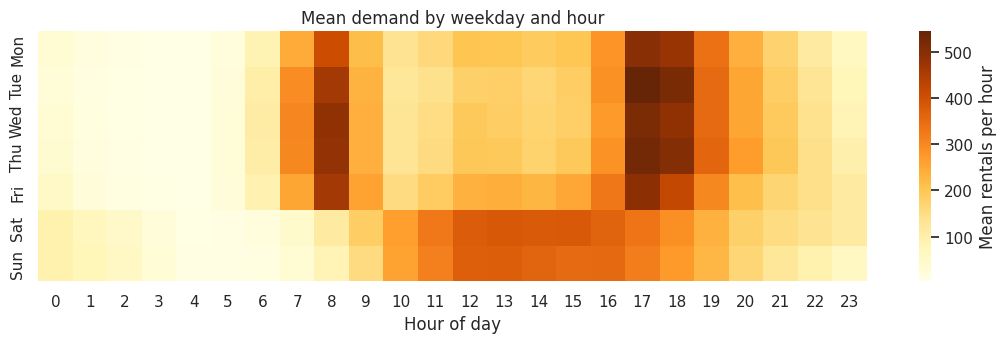

In [8]:
prof = df.groupby(["workingday", "hr"])[["casual", "registered"]].mean()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, wd, ttl in zip(axes, [1, 0], ["Working days", "Weekends and holidays"]):
    p = prof.loc[wd]; ax.plot(p.index, p["registered"], "o-", color=BLUE, label="registered"); ax.plot(p.index, p["casual"], "o-", color=ORANGE, label="casual"); ax.set(title=ttl, xlabel="Hour of day", xticks=range(0, 24, 3))
axes[0].set_ylabel("Mean rentals per hour"); axes[0].legend()
save_fig(fig, "t6_05_daily_profile.png")
tot = df.groupby(["workingday", "hr"])["cnt"].mean().unstack(0); M["peak_working"] = {"hour_am": int(tot[1].loc[6:10].idxmax()), "am": float(tot[1].loc[6:10].max()), "hour_pm": int(tot[1].loc[15:20].idxmax()), "pm": float(tot[1].loc[15:20].max()), "midday": float(tot[1].loc[11:15].mean())}
M["peak_weekend"] = {"hour": int(tot[0].idxmax()), "value": float(tot[0].max())}; M["night_low"] = float(tot[1].loc[2:4].mean())
print(f"Working days: peaks at {M['peak_working']['hour_am']}:00 ({M['peak_working']['am']:.0f}) and {M['peak_working']['hour_pm']}:00 ({M['peak_working']['pm']:.0f}); midday trough ~{M['peak_working']['midday']:.0f}. Weekends: single midday/afternoon plateau peaking at {M['peak_weekend']['hour']}:00 ({M['peak_weekend']['value']:.0f}).")
day_share = df.groupby(df.index.normalize()).agg(c=("casual", "sum"), t=("cnt", "sum"), w=("workingday", "first")); day_share["share"] = day_share["c"] / day_share["t"]
u, p_u = stats.mannwhitneyu(day_share.loc[day_share.w == 0, "share"], day_share.loc[day_share.w == 1, "share"])
M["casual_share"] = {"working": float(day_share.loc[day_share.w == 1, "c"].sum() / day_share.loc[day_share.w == 1, "t"].sum()), "nonworking": float(day_share.loc[day_share.w == 0, "c"].sum() / day_share.loc[day_share.w == 0, "t"].sum()), "p": float(p_u)}
print(f"Casual riders are {M['casual_share']['nonworking']:.1%} of weekend/holiday demand vs {M['casual_share']['working']:.1%} on working days (daily-share Mann-Whitney p = {p_u:.2g}).")
heat = df.pivot_table(index="weekday", columns="hr", values="cnt", aggfunc="mean").reindex([1, 2, 3, 4, 5, 6, 0]); heat.index = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
fig, ax = plt.subplots(figsize=(11, 3.6)); sns.heatmap(heat, cmap="YlOrBr", ax=ax, cbar_kws={"label": "Mean rentals per hour"}); ax.set(title="Mean demand by weekday and hour", xlabel="Hour of day", ylabel="")
save_fig(fig, "t6_06_heatmap.png")

### 5.4 Weather

Like-for-like (same year, hour and day type): mist/cloud hours see 89% of clear-weather demand; light rain/snow/storm hours see 52%.


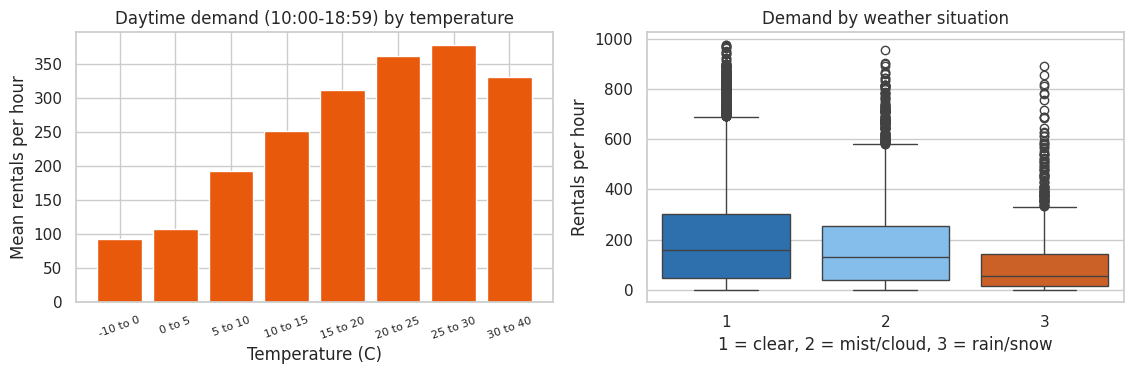

Spearman with demand: {'temp_cnt': 0.43, 'hum_cnt': -0.37, 'wind_cnt': 0.11} | temp vs feels-like: 0.99 -> feels-like is redundant


In [9]:
cellw = df.groupby(["yr", "hr", "workingday", "weathersit"])["cnt"].agg(["mean", "size"]).reset_index()
base = cellw[cellw["weathersit"] == 1].set_index(["yr", "hr", "workingday"])["mean"].rename("base")
ratios = {}
for sit in (2, 3):
    c = cellw[cellw["weathersit"] == sit].join(base, on=["yr", "hr", "workingday"]); c = c[c["base"] > 0]
    ratios[sit] = float(np.average(c["mean"] / c["base"], weights=c["size"]))
M["weather_ratio"] = ratios
print(f"Like-for-like (same year, hour and day type): mist/cloud hours see {ratios[2]:.0%} of clear-weather demand; light rain/snow/storm hours see {ratios[3]:.0%}.")
day = df[df["hr"].between(10, 18)]; bins = [-10, 0, 5, 10, 15, 20, 25, 30, 40]; tb = day.groupby(pd.cut(day["temp_c"], bins), observed=True)["cnt"].agg(["mean", "size"])
M["temp_bins"] = {str(k): {"mean": float(v["mean"]), "n": int(v["size"])} for k, v in tb.iterrows()}
fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.9))
axes[0].bar([f"{int(i.left)} to {int(i.right)}" for i in tb.index], tb["mean"], color=ORANGE); axes[0].set(title="Daytime demand (10:00-18:59) by temperature", xlabel="Temperature (C)", ylabel="Mean rentals per hour"); axes[0].tick_params(axis="x", labelsize=8, rotation=20)
sns.boxplot(data=df, x="weathersit", y="cnt", hue="weathersit", palette=[BLUE, "#74c0fc", ORANGE], legend=False, ax=axes[1]); axes[1].set(title="Demand by weather situation", xlabel="1 = clear, 2 = mist/cloud, 3 = rain/snow", ylabel="Rentals per hour")
save_fig(fig, "t6_07_weather.png")
cm = df[["temp_c", "atemp_c", "hum_pct", "wind_kmh", "cnt"]].corr(method="spearman"); M["spearman"] = {"temp_cnt": float(cm.loc["temp_c", "cnt"]), "hum_cnt": float(cm.loc["hum_pct", "cnt"]), "wind_cnt": float(cm.loc["wind_kmh", "cnt"]), "temp_atemp": float(cm.loc["temp_c", "atemp_c"])}
print("Spearman with demand:", {k: round(v, 2) for k, v in M["spearman"].items() if k != "temp_atemp"}, "| temp vs feels-like:", round(M["spearman"]["temp_atemp"], 3), "-> feels-like is redundant")

### 5.5 Memory in the series: which lags matter?

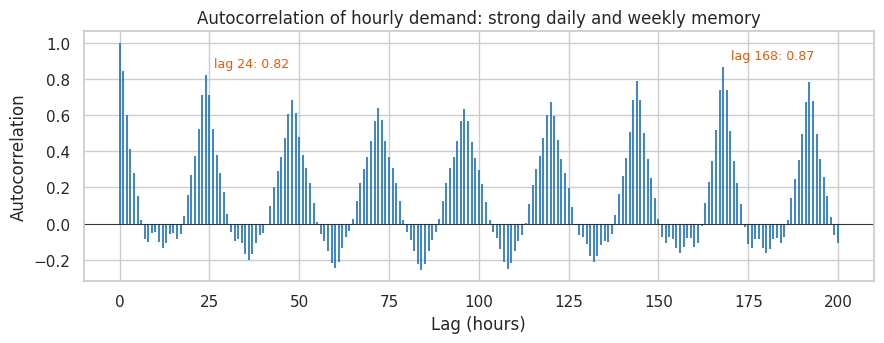

ACF: lag 1h = 0.85, lag 24h = 0.82, lag 168h (same hour last week) = 0.87 -> include day-ahead-safe lags at 24, 48, 168 and 336 hours


In [10]:
ac = acf(df["cnt"], nlags=200, fft=True); M["acf"] = {"lag1": float(ac[1]), "lag24": float(ac[24]), "lag168": float(ac[168])}
fig, ax = plt.subplots(figsize=(9, 3.6)); ax.vlines(range(201), 0, ac, color=BLUE, lw=1.2)
for L in (24, 168): ax.annotate(f"lag {L}: {ac[L]:.2f}", (L, ac[L]), textcoords="offset points", xytext=(6, 6), fontsize=9, color=ORANGE)
ax.set(title="Autocorrelation of hourly demand: strong daily and weekly memory", xlabel="Lag (hours)", ylabel="Autocorrelation"); ax.axhline(0, color="k", lw=.6)
save_fig(fig, "t6_08_acf.png")
print(f"ACF: lag 1h = {ac[1]:.2f}, lag 24h = {ac[24]:.2f}, lag 168h (same hour last week) = {ac[168]:.2f} -> include day-ahead-safe lags at 24, 48, 168 and 336 hours")

### 5.6 Unusual days: wet weather, storms and holidays

Days with demand at least 60% below their 29-day median:


,deficit,worst weathersit,absent hours
ts,,,
2012-10-29,-1.00,3,23
2012-12-26,-0.87,3,0
2011-10-29,-0.85,3,0
2012-04-22,-0.83,3,0
2012-10-30,-0.82,3,13
2011-12-07,-0.79,3,0
2011-04-16,-0.76,3,0
2012-12-24,-0.75,3,1
2011-08-27,-0.75,3,6


17 days fall at least 60% below normal: 14 were mostly rain/snow days, 5 are Christmas-period days (Dec 24-26), the rest are other wet or cold days (categories overlap).
2012-10-29 (Hurricane Sandy): demand -100% versus the typical level


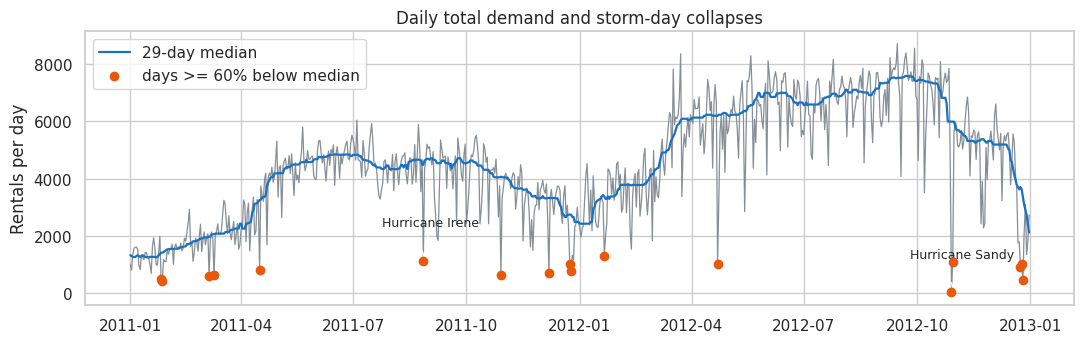

In [11]:
dtot = df["cnt"].groupby(df.index.normalize()).sum(); med = dtot.rolling(29, center=True, min_periods=10).median(); pct = dtot / med - 1
low = pct[pct <= -0.6].sort_values(); wx = df.groupby(df.index.normalize()).agg(sit=("weathersit", "max"), wind=("wind_kmh", "max"), absent=("missing_hour", "sum"))
print("Days with demand at least 60% below their 29-day median:"); display(pd.DataFrame({"deficit": low.round(2), "worst weathersit": wx.loc[low.index, "sit"], "absent hours": wx.loc[low.index, "absent"]}))
wet = (wx.loc[low.index, "sit"] == 3) & (df["weathersit"].groupby(df.index.normalize()).mean().loc[low.index] >= 2.0)
xmas = pd.Series([d.month == 12 and d.day in (24, 25, 26) for d in low.index], index=low.index)
M["low_days"] = {str(k.date()): float(v) for k, v in low.items()}; M["low_days_n"], M["low_days_wet"], M["low_days_christmas"] = int(len(low)), int(wet.sum()), int(xmas.sum())
print(f"{len(low)} days fall at least 60% below normal: {int(wet.sum())} were mostly rain/snow days, {int(xmas.sum())} are Christmas-period days (Dec 24-26), the rest are other wet or cold days (categories overlap).")
sandy = dtot.loc["2012-10-29"] / med.loc["2012-10-29"] - 1; M["sandy_deficit"] = float(sandy); print(f"2012-10-29 (Hurricane Sandy): demand {sandy:.0%} versus the typical level")
fig, ax = plt.subplots(figsize=(11, 3.6)); ax.plot(dtot.index, dtot.values, color=GREY, lw=.9); ax.plot(med.index, med.values, color=BLUE, lw=1.6, label="29-day median")
ax.scatter(low.index, dtot.loc[low.index], color=ORANGE, zorder=5, label="days >= 60% below median")
for d, lab in [("2012-10-29", "Hurricane Sandy"), ("2011-08-27", "Hurricane Irene")]:
    if pd.Timestamp(d) in low.index: ax.annotate(lab, (pd.Timestamp(d), dtot.loc[d]), textcoords="offset points", xytext=(-30, 25), arrowprops=dict(arrowstyle="->"), fontsize=9)
ax.set(title="Daily total demand and storm-day collapses", ylabel="Rentals per day"); ax.legend(loc="upper left")
save_fig(fig, "t6_09_storm_days.png")

### EDA conclusions that shape the modelling
1. Demand is overdispersed and heavy-tailed; point accuracy should be judged with WAPE and intervals should be estimated, not assumed Poisson.
2. Hour-of-day **by day type** is the dominant structure (commuter peaks versus weekend plateau), so models need that interaction.
3. Weather matters like-for-like (rain/storm roughly halves demand; very cold hours are quiet).
4. The system grew rapidly, so a model needs level-adaptive history features (rolling means, lags) rather than only calendar effects.
5. Weekly memory (lag 168 h) is stronger than daily memory, so day-ahead-safe lags are valuable.
6. Wet-weather collapses, hurricanes and Christmas week are real outliers (17 days lose at least 60% of normal demand). They must be reported separately in evaluation, and the **test quarter contains both Hurricane Sandy and Christmas week**.

In [12]:
(ROOT / "outputs" / "eda_metrics.json").write_text(json.dumps(M, indent=2, default=lambda o: o.item() if hasattr(o, "item") else str(o)))
print("saved eda_metrics.json and", len(list(FIG.glob("t6_*.png"))), "figures")

saved eda_metrics.json and 9 figures
